In [1]:
import earthaccess
import os
import warnings
import csv
from osgeo import gdal
import numpy as np
import math
import rasterio as rio
import xarray as xr
import holoviews as hv
import hvplot.xarray
import netCDF4 as nc
#import cv2 as cv

import glob
import sys
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import rasterio
from rasterio.transform import Affine
from scipy import linalg
from lxml import etree
from scipy.ndimage import gaussian_filter, binary_erosion, binary_dilation
from skimage.transform import hough_line, hough_line_peaks

from scipy import ndimage as ndi
from scipy.ndimage import binary_fill_holes, center_of_mass, distance_transform_edt
from scipy.interpolate import PchipInterpolator  # monotone, shape-preserving

from scipy import linalg
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter, binary_erosion, binary_dilation, rotate, shift
from skimage.transform import hough_line, hough_line_peaks
from skimage.restoration import (
    denoise_tv_chambolle,
    denoise_bilateral,
    denoise_wavelet,
    estimate_sigma,
    inpaint_biharmonic
)

wav_min = 403
wav_max = 493
bin_size = 1
polydeg = 3
sys.path.append('../')
from config import CONFIG, LOCS
from REFERENCE_PLANTS import REFERENCE_PLANTS
sys.path.append('../../EMIT-Data-Resources/python/modules/')
from emit_tools import emit_xarray, ortho_xr
help(emit_xarray)

Help on function emit_xarray in module emit_tools:

emit_xarray(filepath, ortho=False, qmask=None, unpacked_bmask=None)
    This function utilizes other functions in this module to streamline opening an EMIT dataset as an xarray.Dataset.
    
    Parameters:
    filepath: a filepath to an EMIT netCDF file
    ortho: True or False, whether to orthorectify the dataset or leave in crosstrack/downtrack coordinates.
    qmask: a numpy array output from the quality_mask function used to mask pixels based on quality flags selected in that function. Any non-orthorectified array with the proper crosstrack and downtrack dimensions can also be used.
    unpacked_bmask: a numpy array from  the band_mask function that can be used to mask band-specific pixels that have been interpolated.
    
    Returns:
    out_xr: an xarray.Dataset constructed based on the parameters provided.



In [2]:
CONFIG

{'data_folder': '/orcd/data/dvaron/001/kgauld/EMIT/data',
 'results_folder': '/orcd/data/dvaron/001/kgauld/EMIT/results6_destriped',
 'plot_folder': '/orcd/data/dvaron/001/kgauld/EMIT/plots6_destriped_recolor',
 'geosfp': '/orcd/data/dvaron/001/kgauld/GEOS_FP',
 'hrrr': '/orcd/data/dvaron/001/kgauld/HRRR',
 'tropomi': '/orcd/data/dvaron/001/kgauld/TROPOMI',
 'campd_key': '/orcd/pool/005/dvaron_shared/kgauld/emit-nox-plumes/secrets/CAMPD_APIKEY',
 'retr_subdir': 'Retrievals',
 'tavg_subdir': 'Time_Average',
 'ps_subdir': 'Point_Source',
 'NOX_CSEC': '/orcd/home/002/kgauld/emit-nox-plumes/cross_sections/no2c_97.txt',
 'AMF_LUT': '/orcd/data/dvaron/001/kgauld/AMF/differential_amf.nc'}

In [3]:
# loc_name = 'Intermountain'
loc_name = 'RIYADH_PLANT_9'

if loc_name == 'Intermountain':
    loc_name, granule_name = 'Intermountain', '20241001T191716_2427513_010'
    fn =  '/orcd/data/dvaron/001/kgauld/EMIT/data/Intermountain/EMIT_L1B_RAD_001_20241001T191716_2427513_010.nc'
    loc_data = REFERENCE_PLANTS[loc_name]
    kmboundary = 40
else:
    loc_name, granule_name = 'RIYADH_PLANT_9', '20250613T114019_2516407_025'
    fn = '/orcd/data/dvaron/001/kgauld/EMIT/data/RIYADH_PLANT_9/EMIT_L1B_RAD_001_20250613T114019_2516407_025.nc'
    loc_data = LOCS[loc_name]
    kmboundary = None

rad_ds = emit_xarray(fn)

In [4]:
####################################################################################################
############################## NOX CROSS SECTION ###################################################
####################################################################################################
def gaussian_kernel(x, mu, fwhm_nm):
    """
    Create normalized Gaussian kernel with standard deviation sigma (nm) based on sigma = FWHM/sqrt(2log2)
    """
    # Define standard deviation sigma
    sigma = fwhm_nm / (2.0 * np.sqrt(2.0 * np.log(2.0)))
    # Create kernel
    k = np.exp(-0.5 * ((x - mu) / sigma)**2)
    # Normalize kernel to area = 1
    k /= np.trapz(k, x, dx=0.01)
    return k

def convolve_to_sensor_grid(xs_wav_nm, xs, sensor_wav_nm, sensor_fwhm_nm):
    """
    Convolve high-res cross-section xs_sigma(xs_wav_nm) to sensor grid using per-band Gaussian SRF.
    Returns array of length len(sensor_wav_nm).
    """
    out = np.zeros_like(sensor_wav_nm, dtype=float)
    for i, (mu, fwhm) in enumerate(zip(sensor_wav_nm, sensor_fwhm_nm)):
        # Create normalized Gaussian kernel
        k = gaussian_kernel(xs_wav_nm, mu, fwhm)
        # Apply kernel to absorption cross-section spectrum
        out[i] = np.trapz(k * xs, xs_wav_nm, dx=0.01)
    return out

def get_NOX_cross_sec(emit_ds, wav_min=wav_min, wav_max=wav_max):
    # Get NO2 absorption cross-sections @ 220K from Vandaele et al. (1998)
    # Following TROPOMI NO2 ATBD: https://sentinel.esa.int/documents/247904/2476257/sentinel-5p-tropomi-atbd-no2-data-products
    # Data reference: http://spectrolab.aeronomie.be/no2.htm
    no2_cross_sections = pd.read_csv(
        CONFIG['NOX_CSEC'],
        sep=" ",
        usecols=[3, 4],
        names=["vacuum_wavenumber_cm-1", "cross_section_cm^2/molecule_@220K"],
    )

    # add wavelength column (nm)
    no2_cross_sections["vacuum_wavelength_nm"] = 1e7 / no2_cross_sections["vacuum_wavenumber_cm-1"].values
    
    emit_spec_wlen = emit_ds["wavelengths"].to_numpy().astype(np.float64)
    emit_spec_fwhm = emit_ds["fwhm"].to_numpy().astype(np.float64)
    
    no2_cross_sections_conv = convolve_to_sensor_grid(no2_cross_sections["vacuum_wavelength_nm"], 
                                                      no2_cross_sections["cross_section_cm^2/molecule_@220K"],
                                                      emit_spec_wlen,
                                                      emit_spec_fwhm)
    
    # Select bands and convolved cross-sections in fitting window
    window_sel = (emit_spec_wlen >= wav_min) & (emit_spec_wlen <= wav_max)
    emit_vnir_spectral_bands_fitting_window = emit_spec_wlen[window_sel].copy()
    no2_cross_sections_conv_fitting_window = no2_cross_sections_conv[window_sel].copy()

    return no2_cross_sections_conv_fitting_window, emit_vnir_spectral_bands_fitting_window

In [5]:
def get_envi_mask(fn):
    mask_fn = fn.replace("L1B_RAD", "L2A_MASK")
    mask_ds = emit_xarray(mask_fn, ortho=False)
    cloud_mask = mask_ds['mask'].values[...,0]
    cloud_mask = binary_dilation(cloud_mask, iterations=2)
    
    cirrus_mask = mask_ds['mask'].values[...,1]
    water_mask = mask_ds['mask'].values[...,2]
    sc_mask = mask_ds['mask'].values[...,3]
    
    agg_mask = np.clip(cloud_mask+cirrus_mask+water_mask+sc_mask, 0, 1)
    del mask_ds
    return agg_mask.astype(np.uint8)

env_mask = get_envi_mask(fn)

In [6]:
nox_window, desired_bands = get_NOX_cross_sec(rad_ds)

emit_window = rad_ds.sel(wavelengths=desired_bands, method='nearest')

In [7]:
def detrend_spectra(spectra, wavelengths, poly_order=5):
    """Remove low-order polynomial from each spectrum (like DOAS)"""
    n_pixels, n_bands = spectra.shape
    detrended = np.zeros_like(spectra)
    coeffs = np.polynomial.polynomial.polyfit(wavelengths, spectra.T, poly_order)
    baseline = np.polynomial.polynomial.polyval(wavelengths, coeffs)
    detrended = spectra - baseline
    return detrended

def detrend_single(spectrum, wavelengths, poly_order=5):
    """Same for the target vector"""
    coeffs = np.polynomial.polynomial.polyfit(wavelengths, spectrum, poly_order)
    baseline = np.polynomial.polynomial.polyval(wavelengths, coeffs)
    return spectrum - baseline

def run_matched_filter_scene(emit, mask=None):
    """Run matched filter using entire scene for ref spec (one reference)"""
    # Work in log space
    radiance_cube = np.array(emit['radiance'])
    log_cube = np.log(radiance_cube)
    if mask is None:
        mask = np.zeros(log_cube.shape[:-1])
    mask = mask.flatten()
    n_bands = log_cube.shape[-1]
    pixels = log_cube.reshape(-1, n_bands)
    
    # Detrend everything
    wavelengths = np.array(desired_bands)  # your 13-14 band centers
    pixels_dt = detrend_spectra(pixels, wavelengths, poly_order=5)
    target_dt = -detrend_single(nox_window, wavelengths, poly_order=5)
    
    # Now run matched filter on detrended spectra
    mu = pixels_dt[np.where(mask==0)].mean(axis=0)
    Sigma = np.cov(pixels_dt[np.where(mask==0)], rowvar=False)
    inv_Sigma = np.linalg.pinv(Sigma)
    
    y = pixels_dt - mu
    field = (y @ inv_Sigma @ target_dt) / (target_dt.T @ inv_Sigma @ target_dt)
    
    return field.reshape(radiance_cube.shape[:-1])

def run_matched_filter_striping(emit, mask=None):
    """Run matched filter with columnwise striping for reference spectrum"""
    # Work in log space
    radiance_cube = np.array(emit['radiance'])
    log_cube = np.log(radiance_cube)

    # only use pixels within the mask for reference spec.
    if mask is None:
        mask = np.zeros(log_cube.shape[:-1])
    mask = mask.flatten()
    
    n_rows, n_cols, n_bands = log_cube.shape
    pixels = log_cube.reshape(-1, n_bands)

    # Detrend everything
    wavelengths = np.array(desired_bands)
    pixels_dt = detrend_spectra(pixels, wavelengths, poly_order=3)
    target_dt = -detrend_single(nox_window, wavelengths, poly_order=3)

    field = np.zeros((n_rows, n_cols))

    for col in range(n_cols):
        col_pixels = pixels_dt[col::n_cols]  # every pixel in this column
        col_mask = mask[col::n_cols]
        
        good = col_pixels[col_mask == 0] # filter out bad pix

        # Calc. matched filter
        mu_col = good.mean(axis=0)
        Sigma_col = np.cov(good, rowvar=False) + 1e-6 * np.eye(n_bands)
        try:
            inv_Sigma_col = np.linalg.pinv(Sigma_col)
            
            y = col_pixels - mu_col
            col_field = (y @ inv_Sigma_col @ target_dt) / (target_dt.T @ inv_Sigma_col @ target_dt)
            field[:, col] = col_field  # or reshape appropriately
        except:
            field[:, col] = np.nan
    return field

In [8]:
def crop_about_loc(ds, clat, clon, km_boundary=None, pix_boundary=None):
    """Crop EMIT granule about the target clat,clon by # of km or pix"""
    if km_boundary is None and pix_boundary is None:
        return np.ones_like(ds['radiance'])[...,0]
    
    lat, lon = ds['lat'], ds['lon']
    
    if km_boundary is not None:
        dlat = (km_boundary/2)/111
        dlon = (km_boundary/2)/(111*np.cos(np.radians(clat)))

        lat_min = clat - dlat
        lat_max = clat + dlat
        lon_min = clon - dlon
        lon_max = clon + dlon

        mask = (
            (lat >= lat_min) & (lat <= lat_max) &
            (lon >= lon_min) & (lon <= lon_max)
        )
        
        ys, xs = np.where(mask)
        if len(ys) == 0:
            raise ValueError("No pixels found inside requested box!")

        y0, y1 = ys.min(), ys.max()
        x0, x1 = xs.min(), xs.max()
    elif pix_boundary is not None:
        plat, plot = np.argmin(np.abs(lat-clat)), np.argmin(np.abs(lon-clon))
        
        y0, y1 = plat - pix_boundary//2, plat + pix_boundary//2
        x0, x1 = plon - pix_boundary//2, plon + pix_boundary//2

    Ny, Nx = ds["radiance"].shape[:2]
        
    mask = np.zeros((Ny, Nx), dtype=bool)
    mask[y0:y1+1, x0:x1+1] = True

    # Expand to (Ny, Nx, Nlam)
    mask3d = mask[..., None]  # shape (Ny, Nx, 1)
    mask3d = np.broadcast_to(mask3d, ds["radiance"].shape)
    
    ds["radiance"] = ds["radiance"].where(mask3d)
    # ds["radiance"] = ds["radiance"].where(mask)

    return mask

cropmask = crop_about_loc(emit_window, loc_data['LAT'], loc_data['LON'], km_boundary=kmboundary)

calibration field done
full field done


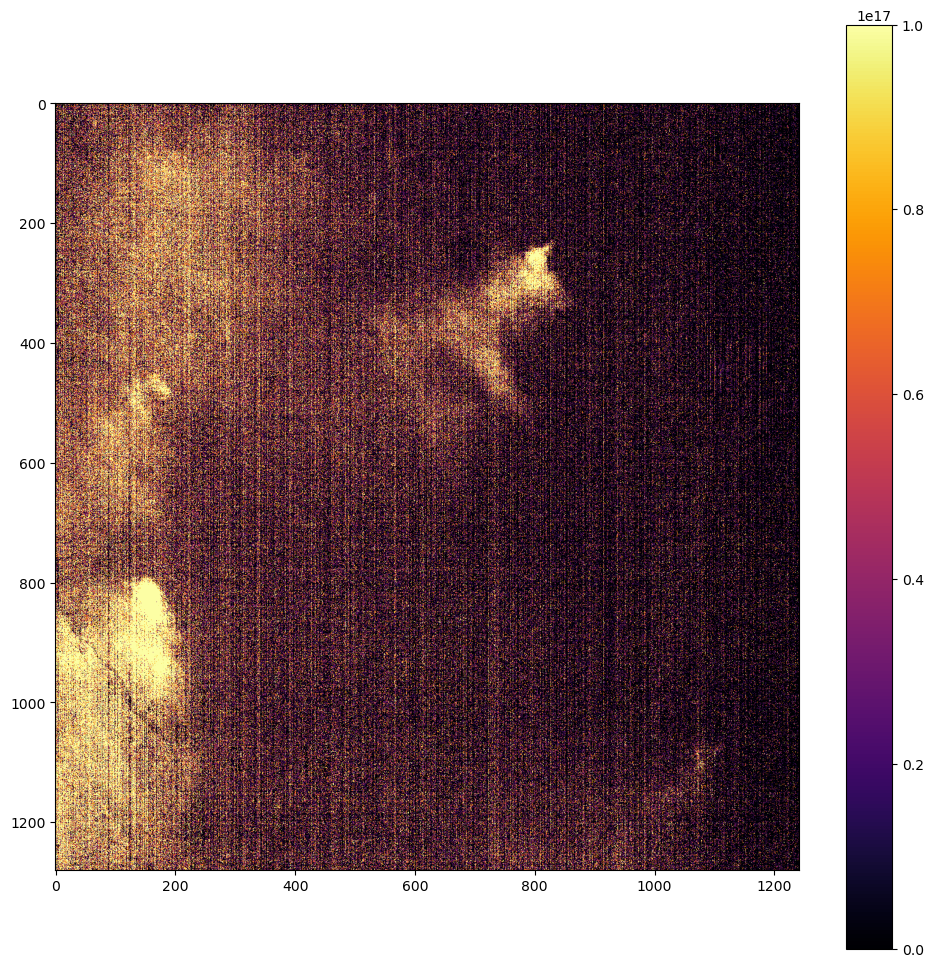

In [9]:
# env_mask_crop = np.clip(env_mask + (1-cropmask), 0, 1).astype(np.uint8)
env_mask_crop = (1-cropmask) 
field = run_matched_filter_scene(emit_window, mask=env_mask_crop)

print('calibration field done')

mask = (field > np.nanpercentile(field, 90)).astype(np.uint8)
mask_comb = np.clip(mask + env_mask_crop, 0, 1).astype(np.uint8)

field_basemf = run_matched_filter_scene(emit_window, mask=mask_comb)
field_basemf[env_mask_crop==1] = np.nan

print('full field done')

plt.figure(figsize=(12,12))
plt.imshow(field_basemf, vmin=0, vmax=1e17, cmap='inferno')
plt.colorbar()

In [10]:
def destripe(cube, mask=None):
    """Remove per-column mean bias from each band. Optionally exclude points from mean bias using mask"""
    cube_norm = cube.copy()
    cube_norm[np.where(mask==1)] = np.nan
    col_mean = np.nanmean(cube_norm, axis=0, keepdims=True)  # (1, C, B)
    row_mean = np.nanmean(cube_norm, axis=(0,1), keepdims=True)  # (1, 1, B) global mean
    return cube - col_mean + row_mean


def run_matched_filter_clusters(emit, clusters, mask=None, use_destripe=False):
    """Run matched filter with a cluster mapping for computing reference spectra"""
    # Work in log space
    radiance_cube = np.array(emit['radiance'])
    log_cube = np.log(radiance_cube)

    if use_destripe:
        log_cube = destripe(log_cube, mask=mask)
    
    if mask is None:
        mask = np.zeros(log_cube.shape[:-1])
    mask = mask.flatten()
    clusters = clusters.flatten()
    n_rows, n_cols, n_bands = log_cube.shape
    pixels = log_cube.reshape(-1, n_bands)
    
    # Detrend everything
    wavelengths = np.array(desired_bands)
    pixels_dt = detrend_spectra(pixels, wavelengths, poly_order=3)
    target_dt = -detrend_single(nox_window, wavelengths, poly_order=3)

    field = np.zeros((n_rows, n_cols)).flatten()

    cluster_ids = np.unique(clusters)
    for c_id in cluster_ids:
        valid_idx = np.where(clusters==c_id)
        c_pixels = pixels_dt[valid_idx]  # every pixel in this cluster
        c_mask = mask[valid_idx]
        
        good = c_pixels[c_mask == 0]
        
        mu_c = good.mean(axis=0)
        Sigma_c = np.cov(good, rowvar=False) + 1e-6 * np.eye(n_bands)
        
        try:
            inv_Sigma_c = np.linalg.pinv(Sigma_c)
            
            y = c_pixels - mu_c
            c_field = (y @ inv_Sigma_c @ target_dt) / (target_dt.T @ inv_Sigma_c @ target_dt)
            field[valid_idx] = c_field  # or reshape appropriately
        except:
            field[valid_idx] = np.nan
    return field.reshape((n_rows, n_cols))

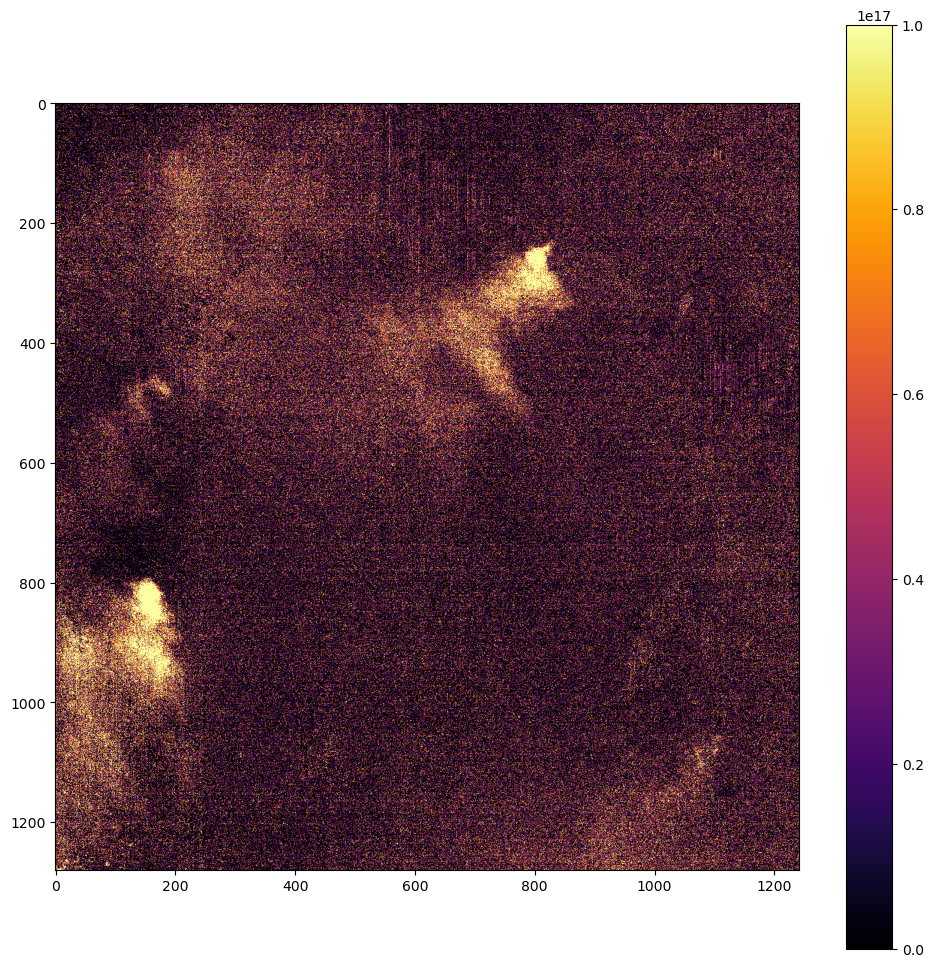

In [11]:
n_rows, n_cols, n_bands = emit_window['radiance'].shape
# Basic way to create clusters along columns-basically getting CMF to work like striping matched filters
colclusters = np.tile(np.linspace(0, n_cols, n_cols), (n_rows, 1)).astype(np.uint16)

# cropmask = crop_about_loc(emit_window, loc_data['LAT'], loc_data['LON'])
env_mask_crop = 1-cropmask
field = run_matched_filter_clusters(emit_window, colclusters, mask=env_mask_crop)

mask = (field > np.nanpercentile(field, 90)).astype(np.uint8)
mask_comb = np.clip(mask + env_mask_crop, 0, 1).astype(np.uint8)

field_mf_striping = run_matched_filter_clusters(emit_window, colclusters, mask=mask_comb)
field_mf_striping[env_mask_crop==1] = np.nan

plt.figure(figsize=(12,12))
plt.imshow(field_mf_striping, vmin=0, vmax=1e17, cmap='inferno')
plt.colorbar()

In [12]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA

def get_clusters(emit, n_clusters=8):
    """K-means clustering on RxCxB hyperspectral image. Returns RxC class map."""
    R, C, B = emit.shape
    pixels = emit.reshape(-1, B)
    mask = np.all(np.isfinite(pixels), axis=1)
    labels = np.full(R * C, -1, dtype=np.int32)

    # reducing each spectrum to a PCA representation to speed up the transform-maintains good representations
    pix_reduced = PCA(n_components=10).fit_transform(pixels[mask])
    labels[mask] = MiniBatchKMeans(n_clusters=n_clusters, batch_size=1024, n_init=10, random_state=0).fit_predict(pix_reduced)
    return labels.reshape(R, C)

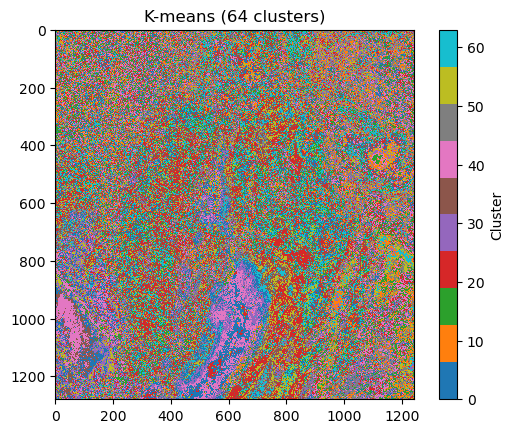

In [13]:
mf_clusters = get_clusters(np.array(emit_window['radiance']), n_clusters=64)

plt.imshow(mf_clusters, cmap='tab10', interpolation='nearest')
plt.colorbar(label='Cluster')
plt.title(f'K-means ({mf_clusters.max()+1} clusters)')
plt.show()

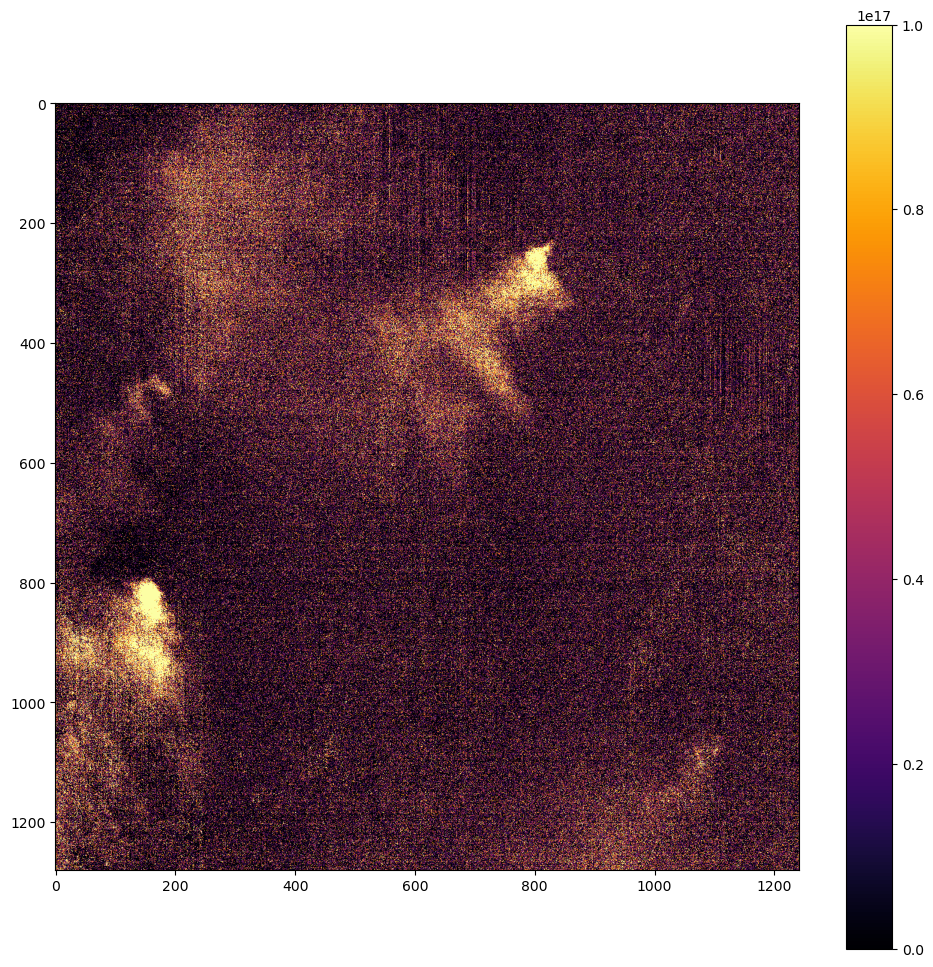

In [14]:
env_mask_crop = 1-cropmask #np.clip(env_mask + (1-cropmask), 0, 1).astype(np.uint8)
field = run_matched_filter_clusters(emit_window, mf_clusters, mask=env_mask_crop, use_destripe=True)

mask = (field > np.nanpercentile(field, 90)).astype(np.uint8)
mask_comb = np.clip(mask + env_mask_crop, 0, 1).astype(np.uint8)

field_mf_cluster = run_matched_filter_clusters(emit_window, mf_clusters, mask=mask_comb, use_destripe=True)
field_mf_cluster[env_mask_crop==1] = np.nan

plt.figure(figsize=(12,12))
plt.imshow(field_mf_cluster, vmin=0, vmax=1e17, cmap='inferno')
plt.colorbar()

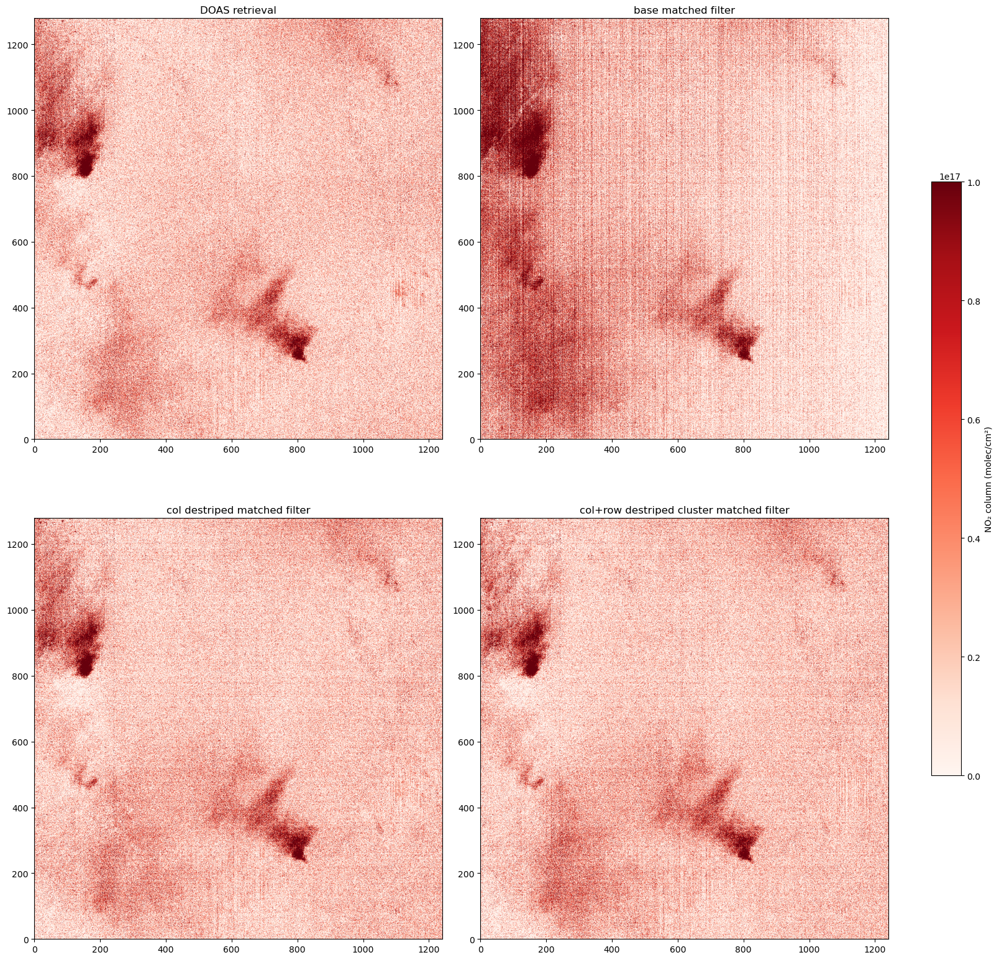

In [15]:
fig, axs=plt.subplots(2,2,layout='constrained',figsize=(16,16))
axs = axs.flatten()

vmin, vmax = 0, 1e17
cmap = 'Reds'

yb, xb = np.where(cropmask==1)
for a in axs:
    a.set_ylim(np.min(yb), np.max(yb))
    a.set_xlim(np.min(xb), np.max(xb))

doas_fpath = f"{CONFIG['results_folder']}/{CONFIG['retr_subdir']}/{loc_name}/dSCD_EMIT_L1B_RAD_001_{granule_name}.npy"
doas = np.load(doas_fpath).astype(np.float32)*1e19

im = axs[0].imshow(doas, vmin=vmin, vmax=vmax, cmap=cmap)
axs[0].set_title('DOAS retrieval')

im=axs[1].imshow(field_basemf, vmin=vmin, vmax=vmax, cmap=cmap)
axs[1].set_title('base matched filter')

im=axs[2].imshow(field_mf_striping, vmin=vmin, vmax=vmax, cmap=cmap)
axs[2].set_title('col destriped matched filter')

im=axs[3].imshow(field_mf_cluster, vmin=vmin, vmax=vmax, cmap=cmap)
axs[3].set_title('col+row destriped cluster matched filter')

fig.colorbar(im, ax=axs.tolist(), shrink=0.6, label='NO₂ column (molec/cm²)')
# plt.savefig('MF_CMP_IM.png', dpi=300, bbox_inches='tight')

# Orthorectifying the field (unused)

In [ ]:
dSCD = field_destriped#field_masked
ds_no_orth = rad_ds

wl_val = float(ds_no_orth["wavelengths"].isel(wavelengths=0))  # or a specific value
dscd_da = xr.DataArray(
    dSCD.astype('float32')[..., None],  # -> (downtrack, crosstrack, 1)
    dims=("downtrack", "crosstrack", "wavelengths"),
    coords={
        "downtrack": ds_no_orth["downtrack"],
        "crosstrack": ds_no_orth["crosstrack"],
        "wavelengths": [wl_val],
    },
    name="dSCD",
    attrs={
        "long_name": "Differential Slant Column Density (single band)",
        "units": "molec cm^-2",
    },
)
ds_no_orth = ds_no_orth.assign(dSCD=dscd_da)
ds = ortho_xr(ds_no_orth)

(dy, dx) = ds.rio.resolution() # in deg
pix_pitch_m = 111000 * abs(dy)

# del ds_no_orth

bounds = (np.min(ds['longitude'].values), np.max(ds['longitude'].values),
          np.min(ds['latitude'].values),  np.max(ds['latitude'].values))

# axs[i].imshow(ds['radiance'][:,:,0], cmap='gray', extent=bounds)
rad1500 = ds['radiance'].sel(wavelengths=1500, method='nearest').values
dSCD_nan = np.where(rad1500 <= -8000, np.nan, ds['dSCD'].values[:,:,0])

valid_lat = ds['latitude'].values[np.where(~np.isnan(dSCD_nan))[0]]
valid_lon = ds['longitude'].values[np.where(~np.isnan(dSCD_nan))[1]]

latmin_bnd, latmax_bnd = valid_lat.min(), valid_lat.max()
lonmin_bnd, lonmax_bnd = valid_lon.min(), valid_lon.max()

print(f"Completed orthorectification")

mask = np.isfinite(dSCD_nan)

_, idx = distance_transform_edt(~mask, return_indices=True)
filled = dSCD_nan[tuple(idx)]/1e19   # copies nearest valid value into each NaN pixel

tv = denoise_tv_chambolle(filled, weight=0.2)
tv[~mask] = np.nan

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,4), layout='constrained')

vlim=1e17

SIGMA=0.5
Z_s   = ndi.gaussian_filter(dSCD_nan, sigma=SIGMA)   # try sigma=0.8–1.5
vlim=max(np.abs(np.nanpercentile(Z_s,70)), np.abs(np.nanpercentile(Z_s,20)))
im = ax[0].imshow(Z_s, cmap='RdBu_r', origin='upper', 
              aspect='auto', extent=bounds,  
                  vmin=-vlim,#np.nanpercentile(Z_s,60), 
                  vmax=vlim)#np.nanpercentile(Z_s,90))
cb = plt.colorbar(im, ax=ax[0])
cb.set_label("NO₂ dSCD (molecules cm⁻²)", fontsize=12)
ax[0].scatter([loc_data['LON']], [loc_data['LAT']], marker='x', c='red')
ax[0].set_title('Retrieved Differential Slant Column Density (dSCD)')

im = ax[1].imshow(tv*1e19, cmap='RdBu_r', origin='upper', 
              aspect='auto', vmin=-vlim, vmax=vlim, extent=bounds)
cb = plt.colorbar(im, ax=ax[1])
cb.set_label("Filtered dSCD", fontsize=12)
ax[1].scatter([loc_data['LON']], [loc_data['LAT']], marker='x', c='red')
ax[1].set_title('dSCD Post-Total Variance (TV) Filter')

for a in ax:
    a.set_xlim(lonmin_bnd, lonmax_bnd)
    a.set_ylim(latmin_bnd, latmax_bnd)

    a.set_ylabel('Latitude')
    a.set_xlabel('Longitude')

plt.show()